In [84]:
!pip install pandas


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [85]:
import pandas as pd

In [86]:
df = pd.read_csv('../webscrape/data/cars.csv')  
df.head()

,brand,model,mileage_km,year,fuel_type,price_eur,transmission,body_type,new_price_eur,new_price_source
0,Audi,A3,339130.0,2005,petrol,2000,manual,hatchback,39408.0,schatting
1,Audi,A2,395000.0,2005,diesel,2200,automatic,hatchback,51235.0,schatting
2,Audi,A3,215632.0,2005,petrol,2444,manual,hatchback,39408.0,schatting
3,Audi,A3,242393.0,2005,petrol,2740,manual,hatchback,39408.0,schatting
4,Audi,A3,235000.0,2005,petrol,2750,manual,hatchback,39408.0,schatting


In [87]:
df["new_price_source"].value_counts()

new_price_source
autoscout       74367
rdw_kenteken    38894
schatting       35341
Name: count, dtype: int64

In [88]:
df["model"].value_counts()

model
Polo            4123
Golf            3596
Tiguan          2957
Focus           2950
A3              2680
                ... 
Freestar           1
F Super Duty       1
Customline         1
Sierra             1
Tourneo            1
Name: count, Length: 669, dtype: int64

In [89]:
df["observation_year"] = 2026


In [90]:
audi_a3 = (
    df[
        (df["brand"] == "Audi") &
        (df["model"] == "A3")
    ]
    .groupby("year", as_index=False)
    .agg(
        avg_price_eur=("price_eur", "mean"),
        avg_mileage_km=("mileage_km", "mean"),
        amount=("price_eur", "count")
    )
    .sort_values("year")
)

audi_a3

,year,avg_price_eur,avg_mileage_km,amount
0,2005,3206.416667,247704.166667,12
1,2006,3149.866667,251399.733333,15
2,2007,4638.214286,218174.357143,14
3,2008,5004.714286,217888.380952,42
4,2009,6232.137931,211518.568966,58
5,2010,6486.872727,211530.909091,55
6,2011,6963.838710,205276.209677,62
7,2012,6731.950000,211373.633333,60
8,2013,10224.330935,194634.553957,139
9,2014,11380.026316,189744.789474,114


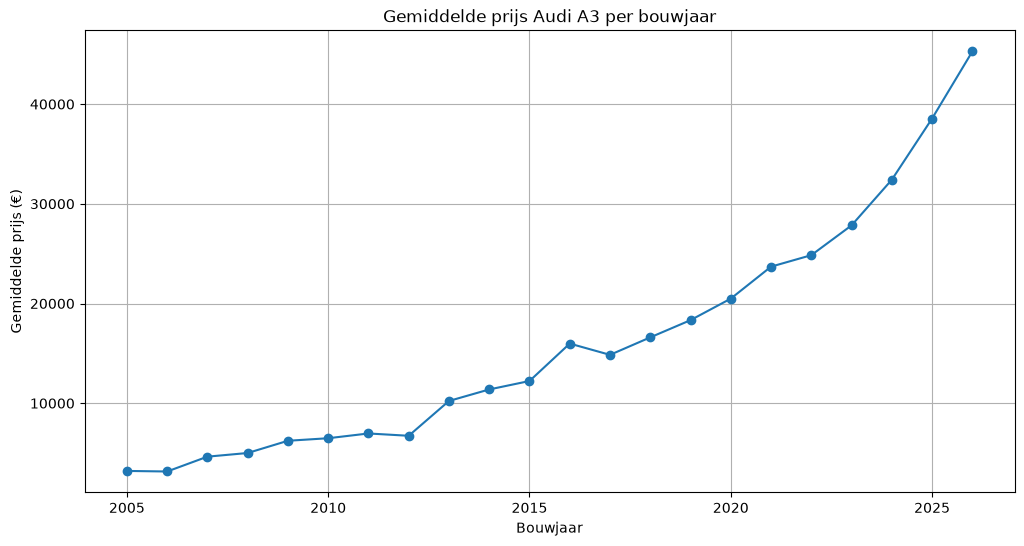

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    audi_a3["year"],
    audi_a3["avg_price_eur"],
    marker="o"
)

plt.xlabel("Bouwjaar")
plt.ylabel("Gemiddelde prijs (€)")
plt.title("Gemiddelde prijs Audi A3 per bouwjaar")
plt.grid(True)
plt.show()

In [92]:
df.head()

,brand,model,mileage_km,year,fuel_type,price_eur,transmission,body_type,new_price_eur,new_price_source,observation_year
0,Audi,A3,339130.0,2005,petrol,2000,manual,hatchback,39408.0,schatting,2026
1,Audi,A2,395000.0,2005,diesel,2200,automatic,hatchback,51235.0,schatting,2026
2,Audi,A3,215632.0,2005,petrol,2444,manual,hatchback,39408.0,schatting,2026
3,Audi,A3,242393.0,2005,petrol,2740,manual,hatchback,39408.0,schatting,2026
4,Audi,A3,235000.0,2005,petrol,2750,manual,hatchback,39408.0,schatting,2026


In [93]:
df.nlargest(20, "price_eur")[
    ["brand", "model", "year", "mileage_km", "new_price_eur", "price_eur"]
]

,brand,model,year,mileage_km,new_price_eur,price_eur
40247,Mercedes-Benz,Vito,2015,237872.0,41230.0,99999999
18741,BMW,218,2014,184000.0,32847.0,7500000
52759,Mercedes-Benz,AMG ONE,2025,10.0,NaN,3387950
145546,Porsche,Carrera GT,2006,14314.0,139599.0,2999950
45031,Mercedes-Benz,AMG GT,2020,3676.0,895000.0,1250000
85909,Volvo,XC60,2016,210872.0,63095.0,1195000
39053,Mercedes-Benz,G 63 AMG,2014,703.0,262278.0,1090000
140142,Peugeot,3008,2021,111948.0,42310.0,999999
141161,Peugeot,e-2008,2022,110923.0,40080.0,999999
42525,Mercedes-Benz,G 650,2018,405.0,NaN,949500


In [94]:
df = df.drop(index=[40247, 140142, 141161, 85909, 18741])

In [95]:
df.nlargest(20, "price_eur")[
    ["brand", "model", "year", "mileage_km", "new_price_eur", "price_eur"]
]

,brand,model,year,mileage_km,new_price_eur,price_eur
52759,Mercedes-Benz,AMG ONE,2025,10.0,NaN,3387950
145546,Porsche,Carrera GT,2006,14314.0,139599.0,2999950
45031,Mercedes-Benz,AMG GT,2020,3676.0,895000.0,1250000
39053,Mercedes-Benz,G 63 AMG,2014,703.0,262278.0,1090000
42525,Mercedes-Benz,G 650,2018,405.0,NaN,949500
36684,Mercedes-Benz,SLR,2008,24933.0,689112.0,799995
48124,Mercedes-Benz,AMG GT,2022,4875.0,575237.0,629880
145849,Porsche,911,2011,5593.0,165074.0,625000
48123,Mercedes-Benz,AMG GT,2022,80.0,208573.0,599900
105740,Ford,GT,2006,56644.0,71752.0,549950


In [96]:
df.isna().sum()

brand                 0
model                 7
mileage_km          407
year                  0
fuel_type             0
price_eur             0
transmission          0
body_type             0
new_price_eur        60
new_price_source     60
observation_year      0
dtype: int64

In [97]:
df = df.dropna()

In [98]:
df.duplicated().sum()

np.int64(4436)

In [99]:
df_encoded = pd.get_dummies(
    df,
    columns=["brand", "model", "fuel_type", "transmission", "body_type"],
    dtype=int
)

In [100]:
df_encoded.head()

,mileage_km,year,price_eur,new_price_eur,new_price_source,observation_year,brand_Audi,brand_BMW,brand_Ford,brand_Mercedes-Benz,...,transmission_other,body_type_convertible,body_type_coupe,body_type_hatchback,body_type_mpv,body_type_other,body_type_sedan,body_type_station_wagon,body_type_suv,body_type_van
0,339130.0,2005,2000,39408.0,schatting,2026,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1,395000.0,2005,2200,51235.0,schatting,2026,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,215632.0,2005,2444,39408.0,schatting,2026,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,242393.0,2005,2740,39408.0,schatting,2026,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
4,235000.0,2005,2750,39408.0,schatting,2026,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0


In [101]:
df_encoded = df_encoded.sort_values("year").reset_index(drop=True)

In [102]:
df.columns

Index(['brand', 'model', 'mileage_km', 'year', 'fuel_type', 'price_eur',
       'transmission', 'body_type', 'new_price_eur', 'new_price_source',
       'observation_year'],
      dtype='str')

In [103]:
X = df_encoded.drop(columns=["price_eur"])
y = df_encoded["price_eur"]

train_size = int(len(df_encoded) * 0.70)
val_size = int(len(df_encoded) * 0.15)

X_train = X.iloc[:train_size]
y_train = y.iloc[:train_size]

X_val = X.iloc[train_size:train_size + val_size]
y_val = y.iloc[train_size:train_size + val_size]

X_test = X.iloc[train_size + val_size:]
y_test = y.iloc[train_size + val_size:]

In [104]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (103730, 679) (103730,)
Validation: (22228, 679) (22228,)
Test: (22229, 679) (22229,)


In [105]:
df.head()

,brand,model,mileage_km,year,fuel_type,price_eur,transmission,body_type,new_price_eur,new_price_source,observation_year
0,Audi,A3,339130.0,2005,petrol,2000,manual,hatchback,39408.0,schatting,2026
1,Audi,A2,395000.0,2005,diesel,2200,automatic,hatchback,51235.0,schatting,2026
2,Audi,A3,215632.0,2005,petrol,2444,manual,hatchback,39408.0,schatting,2026
3,Audi,A3,242393.0,2005,petrol,2740,manual,hatchback,39408.0,schatting,2026
4,Audi,A3,235000.0,2005,petrol,2750,manual,hatchback,39408.0,schatting,2026


In [106]:
numeric_cols = [
    "mileage_km",
    "year",
    "new_price_eur",
    "observation_year"
]

In [107]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Maak copies om warnings/problemen te voorkomen
X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

# Fit ALLEEN op train
X_train[numeric_cols] = scaler.fit_transform(
    X_train[numeric_cols]
)

# Gebruik dezelfde scaler voor validation en test
X_val[numeric_cols] = scaler.transform(
    X_val[numeric_cols]
)

X_test[numeric_cols] = scaler.transform(
    X_test[numeric_cols]
)

In [108]:
X_train.head()

,mileage_km,year,new_price_eur,new_price_source,observation_year,brand_Audi,brand_BMW,brand_Ford,brand_Mercedes-Benz,brand_Opel,...,transmission_other,body_type_convertible,body_type_coupe,body_type_hatchback,body_type_mpv,body_type_other,body_type_sedan,body_type_station_wagon,body_type_suv,body_type_van
0,2.641100,-2.667698,-0.279199,schatting,0.0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1,1.818164,-2.667698,0.556781,schatting,0.0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
2,1.094180,-2.667698,-0.026497,schatting,0.0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,1.270858,-2.667698,0.556781,rdw_kenteken,0.0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
4,1.531259,-2.667698,0.301175,schatting,0.0,0,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [109]:
X_train[numeric_cols].describe()

,mileage_km,year,new_price_eur,observation_year
count,1.037300e+05,1.037300e+05,1.037300e+05,103730.0
mean,9.644695e-17,2.028893e-14,4.383952e-17,0.0
std,1.000005e+00,1.000005e+00,1.000005e+00,0.0
min,-1.713627e+00,-2.667698e+00,-1.217065e+00,0.0
25%,-6.914421e-01,-7.084974e-01,-5.315453e-01,0.0
50%,-1.637992e-01,1.622583e-01,-2.244844e-01,0.0
75%,5.206794e-01,8.153250e-01,1.992415e-01,0.0
max,3.680911e+01,1.250703e+00,9.878606e+01,0.0


In [110]:
!pip install pyarrow


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [111]:
# Features opslaan
X_train.to_parquet("X_train.parquet", index=False)
X_val.to_parquet("X_val.parquet", index=False)
X_test.to_parquet("X_test.parquet", index=False)

# Targets opslaan
y_train.to_frame().to_parquet("y_train.parquet", index=False)
y_val.to_frame().to_parquet("y_val.parquet", index=False)
y_test.to_frame().to_parquet("y_test.parquet", index=False)